# When does a quantum kernel have a chance?
A small, reproducible comparison on balanced breast-cancer data and a circles
control. This notebook opens the saved validated results. Set `RERUN = True`
to rerun the benchmark with the current Python environment (several minutes).

## Protocol
One stratified 112/48 split from 160 samples, seed 0. Every method sees the
same features and the same 5-fold × 3-repeat outer splits. Standardization,
PCA and angle scaling are fit inside each inner training fold. Inner 3-fold
CV tunes classical hyperparameters and quantum map, repetitions, bandwidth,
and SVM C. The final holdout fits tune on training data only.

The holdout was already examined during development, so it is a descriptive
comparison rather than fresh confirmation. Fold SD is not a confidence interval.

In [1]:
from pathlib import Path
import sys
import subprocess
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/qkb").is_dir())
sys.path.insert(0, str(ROOT / "src"))
RERUN = False
if RERUN:
    subprocess.run([sys.executable, "scripts/run_benchmark.py"], cwd=ROOT, check=True)
    subprocess.run([sys.executable, "scripts/run_benchmark.py", "--dataset", "circles"], cwd=ROOT, check=True)
    subprocess.run([sys.executable, "scripts/make_figures.py"], cwd=ROOT, check=True)

,model,family,cv_acc,cv_std,cv_f1,test_acc
0,SVM-RBF,classical,0.9432,0.0530,0.9450,0.9375
1,SVM-linear,classical,0.9611,0.0362,0.9622,0.9375
2,LogReg,classical,0.9669,0.0350,0.9683,0.9167
3,RandomForest,classical,0.9519,0.0481,0.9522,0.9375
4,MLP,classical,0.9730,0.0362,0.9741,0.8958
5,QKernel-SVM (nested selection),quantum,0.9610,0.0326,0.9625,0.9375


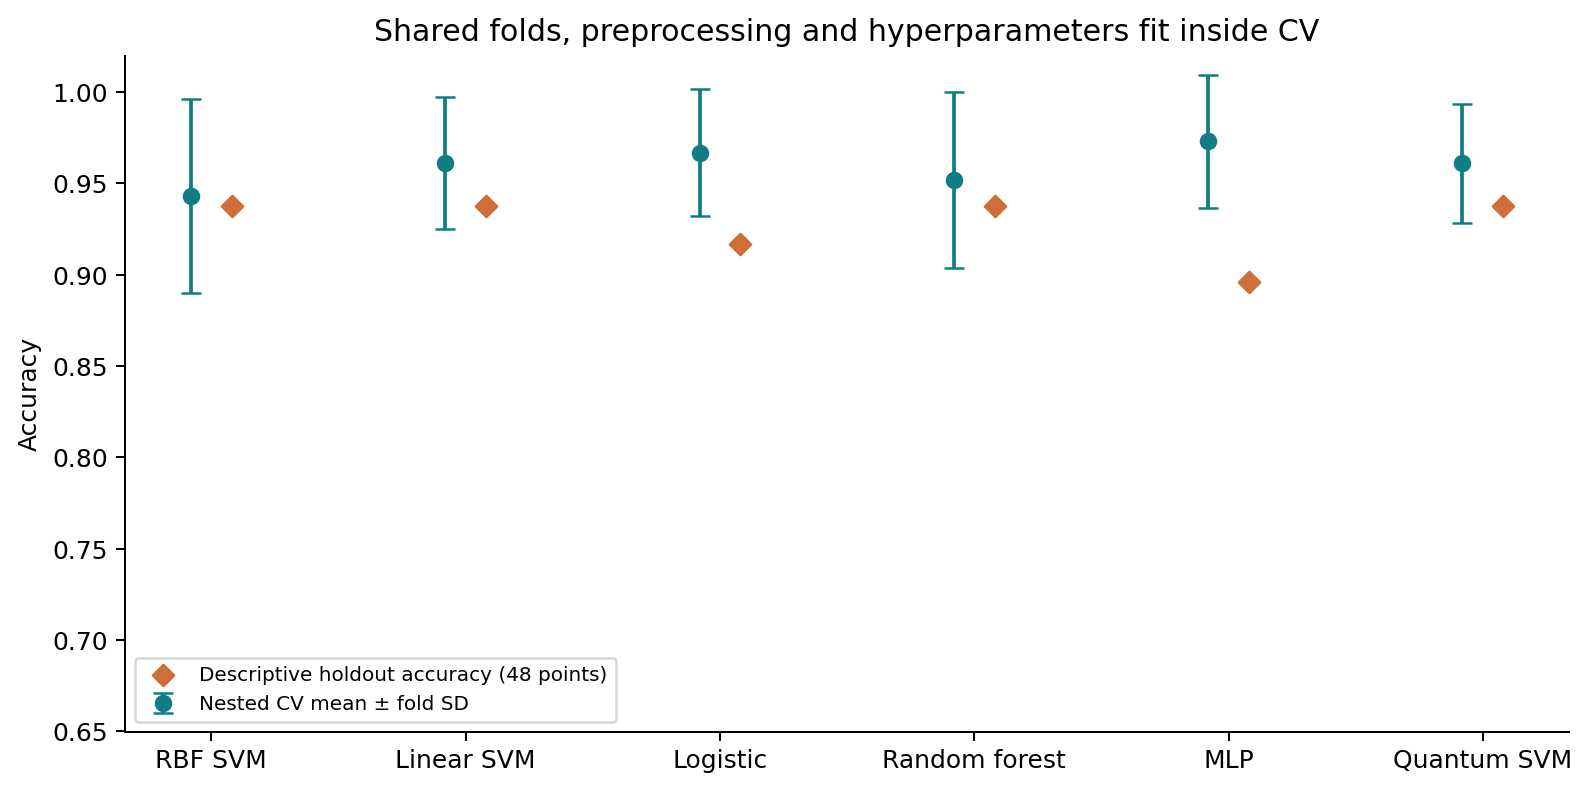

In [2]:
benchmark = pd.read_csv(ROOT / "results/breast_cancer_4q/benchmark.csv")
display(benchmark.round(4))
display(Image(filename=str(ROOT / "figures/benchmark.png")))

## Paired comparison
The quantum row evaluates the entire selection procedure. The map may change
across outer folds. Differences below are paired on identical folds; repeated
folds share data, so a naive independent-fold t-test would overstate certainty.

In [3]:
paired = pd.read_csv(ROOT / "results/breast_cancer_4q/paired_comparisons.csv")
display(paired.drop(columns="note").round(4))

,comparator,mean_delta,std_delta,quantum_wins,ties,classical_wins
0,SVM-RBF,0.0178,0.0317,4,11,0
1,SVM-linear,-0.0001,0.0162,1,13,1
2,LogReg,-0.0059,0.0151,0,13,2
3,RandomForest,0.0091,0.0293,3,11,1
4,MLP,-0.0120,0.0199,0,11,4


## Where classical wins
Compare RBF SVM with the nested quantum selection procedure, not with the
largest score among 36 exploratory curves. The Z map has no entangling gates
and admits efficient classical simulation. A strong Z result does not establish
a quantum computational advantage. At this sample size, individual test
differences are coarse (one sample is 1/48 ≈ 2.08 percentage points).

,model,family,cv_acc,cv_std,cv_f1,test_acc
0,SVM-RBF,classical,0.9971,0.0108,0.9973,1.0000
1,SVM-linear,classical,0.5721,0.0963,0.6414,0.5417
2,LogReg,classical,0.4557,0.1103,0.4636,0.4167
3,RandomForest,classical,0.9759,0.0365,0.9750,0.9792
4,MLP,classical,0.9823,0.0350,0.9839,1.0000
5,QKernel-SVM (nested selection),quantum,0.9970,0.0113,0.9971,1.0000


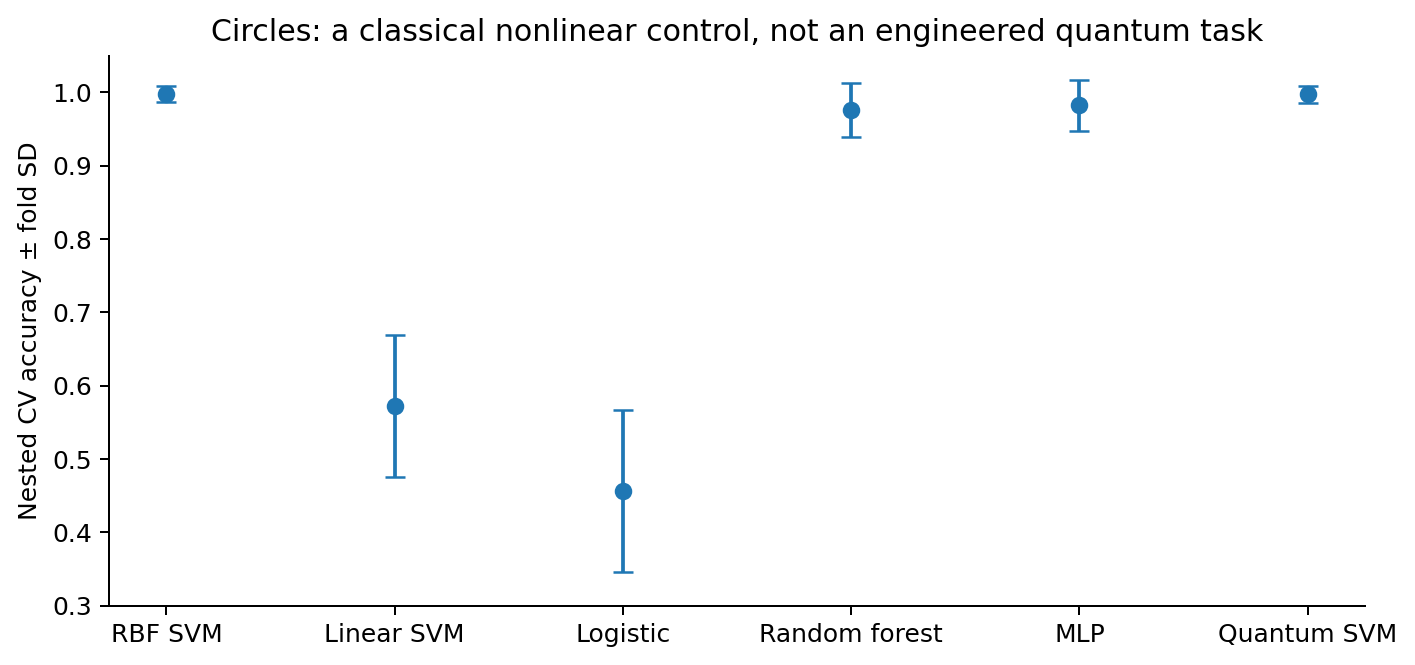

In [4]:
display(pd.read_csv(ROOT / "results/circles_2q/benchmark.csv").round(4))
display(Image(filename=str(ROOT / "figures/circles_control.png")))

Circles is a control for ordinary nonlinear structure. It is not a synthetic
task constructed to favor a quantum kernel. See README for measured outcomes
and `summary.json` for every split index and selected configuration.